# Task 2 — Baselines (Exercise B, 17 gestures)

This notebook covers: subject-independent split, preprocessing checks, seven baselines, full metrics with training time,
overfitting check, channel importance, per-gesture F1, confusion matrix, classification report, inference time and model size.

## 1. Data loading and subject split 

In [1]:
# 1. SETUP
import os, re, glob, warnings
import numpy as np, pandas as pd, scipy.io as sio
import matplotlib.pyplot as plt, seaborn as sns, networkx as nx
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from scipy.stats import skew, kurtosis
import plotly.express as px
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")

DATA_ROOT = os.environ.get("NINAPRO_ROOT", "/kaggle/input")
FS, WIN, SEED = 2000, 400, 42          # 2000 Hz, window = 400 samples (200 ms)
rng = np.random.default_rng(SEED)
CH = [f"ch{i:02d}" for i in range(1, 13)]

In [2]:
# 2. FIND FILES
pat = re.compile(r"S(\d+)_E(\d+)_A\d+\.mat$")
paths = sorted(glob.glob(f"{DATA_ROOT}/**/S*_E*_A*.mat", recursive=True))
files = pd.DataFrame([(p, int(m[1]), int(m[2])) for p in paths if (m := pat.search(p))],
                     columns=["path", "subject", "exercise"])
assert len(files) > 0, "No .mat files found"

print(f"Files: {len(files)} | Subjects: {files.subject.nunique()} | Exercises: {sorted(files.exercise.unique().tolist())}")
print(f"12 EMG channels, {FS} Hz, window = {WIN} samples = {WIN*1000//FS} ms")

Files: 120 | Subjects: 40 | Exercises: [1, 2, 3]
12 EMG channels, 2000 Hz, window = 400 samples = 200 ms


In [3]:
# 3. LOAD EVERYTHING ONCE (one file at a time, to save memory)
samples, wins, segs, n_bad, n_total = [], [], [], 0, 0

for f in files.itertuples():
    m = sio.loadmat(f.path, variable_names=["emg", "restimulus", "rerepetition"])
    emg = m["emg"].astype(np.float32)
    lab, rep = m["restimulus"].ravel(), m["rerepetition"].ravel()
    n_bad += int((~np.isfinite(emg)).sum()); n_total += emg.size

    # 4000 random raw samples (for stats + plots)
    s = pd.DataFrame(emg[rng.choice(len(emg), min(4000, len(emg)), replace=False)], columns=CH)
    s["subject"] = f.subject 
    samples.append(s)

    # one segment = one gesture in one repetition
    cut = np.flatnonzero((np.diff(lab) != 0) | (np.diff(rep) != 0)) + 1
    for a, b in zip(np.r_[0, cut], np.r_[cut, len(lab)]):
        segs.append((f.subject, f.exercise, int(lab[a]), b - a))
        if lab[a] > 0 and b - a >= WIN:                      # active gesture -> take 1 random window
            st = rng.integers(a, b - WIN + 1)
            wins.append((f.subject, f.exercise, int(lab[a]), np.sqrt((emg[st:st+WIN] ** 2).mean(0))))  # RMS per channel

samp = pd.concat(samples, ignore_index=True)
seg = pd.DataFrame(segs, columns=["subject", "exercise", "label", "length"])
win = pd.DataFrame([w[:3] for w in wins], columns=["subject", "exercise", "label"])
rms = pd.DataFrame([w[3] for w in wins], columns=CH)        # window feature = RMS of each channel

print(f"Loaded {len(files)} files, {n_total/12:,.0f} samples per channel")
print(f"Segments: {len(seg):,} | Windows used for analysis: {len(win):,} (RMS feature, 12 channels)")

Loaded 120 files, 207,713,115 samples per channel
Segments: 23,640 | Windows used for analysis: 11,760 (RMS feature, 12 channels)


In [4]:
# 4. SPLIT SUBJECTS (train / val / test) - do this BEFORE fitting anything
subj = rng.permutation(sorted(win.subject.unique()))
n_test, n_val = max(1, round(0.2 * len(subj))), max(1, round(0.1 * len(subj)))
test, val, train = subj[:n_test], subj[n_test:n_test + n_val], subj[n_test + n_val:]
assert not set(train) & set(val) and not set(train) & set(test) and not set(val) & set(test)

is_train = win.subject.isin(train).values
print("[OK] No subject appears in two groups (no leakage)")
print(f"train: {len(train)} subjects | val: {len(val)} subjects | test: {len(test)} subjects")
print(f"windows -> train: {is_train.sum():,} | val: {win.subject.isin(val).sum():,} | test: {win.subject.isin(test).sum():,}")
print("Everything below that is 'fitted' (scaler, PCA, correlation) uses TRAIN subjects only.")

# train-only views: every statistic / plot / fitted object in A-H comes from these
split    = np.where(is_train, "train", np.where(win.subject.isin(val), "val", "test"))
samp_tr  = samp[samp.subject.isin(train)][CH]       # raw samples, train subjects
win_tr   = win[is_train]                            # window labels, train subjects
rms_tr   = rms[is_train]                            # RMS features, train subjects
seg_tr   = seg[seg.subject.isin(train)]             # segments, train subjects

[OK] No subject appears in two groups (no leakage)
train: 28 subjects | val: 4 subjects | test: 8 subjects
windows -> train: 8,232 | val: 1,176 | test: 2,352
Everything below that is 'fitted' (scaler, PCA, correlation) uses TRAIN subjects only.


In [5]:
# quick look at the structure we just described
per_subj = win.groupby("subject").size()
print(f"Subjects: {win.subject.nunique()} | windows per subject: min {per_subj.min()}, mean {per_subj.mean():.0f}, max {per_subj.max()}")
print(f"Graph per sample: {len(CH)} nodes (one per electrode), 1 feature per node (window RMS)")
display(win.assign(split=split).groupby("split").agg(subjects=("subject", "nunique"), windows=("label", "size"), gestures=("label", "nunique")))

Subjects: 40 | windows per subject: min 294, mean 294, max 294
Graph per sample: 12 nodes (one per electrode), 1 feature per node (window RMS)


,subjects,windows,gestures
split,,,
test,8,2352,49
train,28,8232,49
val,4,1176,49


## 2. Exercise B data and preprocessing
Exercise B = exercise 1 of DB2 (17 gestures). Only this exercise is used in Task 2.

#  Data preparation: log, scaling (train only), encoding

In [6]:
# Exercise B data (exercise 1 in DB2), same subject split as Task 1
from sklearn.preprocessing import LabelEncoder

mB = (win.exercise == 1).values
X  = np.log(rms.values[mB] + 1e-9)                 # log fixes skew
le = LabelEncoder(); y = le.fit_transform(win.label.values[mB])   # 0..16
sp = split[mB]
tr, va, te = sp == "train", sp == "val", sp == "test"

scaler = StandardScaler().fit(X[tr])               # fit on TRAIN only
Xtr, Xva, Xte = scaler.transform(X[tr]), scaler.transform(X[va]), scaler.transform(X[te])
ytr, yva, yte = y[tr], y[va], y[te]

print(f"Exercise B: {len(y)} windows, {len(le.classes_)} classes")
print(f"train {len(ytr)} | val {len(yva)} | test {len(yte)}  (subject-wise, no leakage)")
print(f"class count per class (train): min {np.bincount(ytr).min()}, max {np.bincount(ytr).max()}")
print(f"random guess accuracy = {1/len(le.classes_):.3f}")

Exercise B: 4080 windows, 17 classes
train 2856 | val 408 | test 816  (subject-wise, no leakage)
class count per class (train): min 168, max 168
random guess accuracy = 0.059


# Preprocessing checklist 

In [7]:
from sklearn.feature_selection import f_classif

subj_B = win.subject.values[mB]                              # subject id of every Exercise B window
s_tr, s_va, s_te = (set(subj_B[m]) for m in (tr, va, te))
cnt = np.bincount(ytr)                                       # windows per class (train)
F, pval = f_classif(Xtr, ytr)                                # ANOVA F-test per channel (train only)
weak = [c for c, p in zip(CH, pval) if p >= 0.05]

no_overlap = not (s_tr & s_va or s_tr & s_te or s_va & s_te)
finite     = bool(np.isfinite(X).all())
scaler_ok  = np.allclose(scaler.mean_, X[tr].mean(0))        # True only if the scaler saw TRAIN windows only
balanced   = cnt.max() / cnt.min() < 1.5

checks = pd.DataFrame([
    ("Subject-independent split", f"{len(s_tr)} / {len(s_va)} / {len(s_te)} subjects (train / val / test)",
     "no subject appears in two groups" if no_overlap else "LEAKAGE: fix the split", no_overlap),
    ("Missing values", f"{int((~np.isfinite(X)).sum())} non-finite values in the features",
     "no imputation needed" if finite else "impute or remove these windows", finite),
    ("Scaling", "log(RMS) + StandardScaler",
     "scaler was fitted on TRAIN windows only" if scaler_ok else "LEAKAGE: scaler saw other data", scaler_ok),
    ("Encoding", f"{len(le.classes_)} gestures mapped to labels {y.min()}..{y.max()}",
     "LabelEncoder (classes are not ordered, so no ordinal meaning is used)", True),
    ("Class imbalance", f"train windows per class: min {cnt.min()}, max {cnt.max()}",
     "balanced: no resampling or class weights needed" if balanced else "imbalanced: use class weights / macro metrics", balanced),
    ("Feature selection", f"{len(CH) - len(weak)} / {len(CH)} channels are significant (ANOVA, train only)",
     "keep all channels (each channel is a graph node)" if not weak else f"consider dropping: {weak}", True),
], columns=["Step", "Result", "Decision", "OK"])
display(checks)
print("All checks passed" if checks.OK.all() else "Some checks failed - see the table")
display(pd.DataFrame({"F_score": F, "p_value": pval}, index=CH).sort_values("F_score", ascending=False).round(4))

,Step,Result,Decision,OK
0,Subject-independent split,28 / 4 / 8 subjects (train / val / test),no subject appears in two groups,True
1,Missing values,0 non-finite values in the features,no imputation needed,True
2,Scaling,log(RMS) + StandardScaler,scaler was fitted on TRAIN windows only,True
3,Encoding,17 gestures mapped to labels 0..16,"LabelEncoder (classes are not ordered, so no o...",True
4,Class imbalance,"train windows per class: min 168, max 168",balanced: no resampling or class weights needed,True
5,Feature selection,"12 / 12 channels are significant (ANOVA, train...",keep all channels (each channel is a graph node),True


All checks passed


,F_score,p_value
ch11,62.0071,0.0
ch04,38.6083,0.0
ch09,29.0493,0.0
ch05,28.6039,0.0
ch01,26.1975,0.0
ch03,24.8289,0.0
ch02,23.1222,0.0
ch08,14.8998,0.0
ch10,11.4421,0.0
ch12,11.2773,0.0


# 3. Baselines: metrics and training time

In [8]:
# baselines
import time
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, confusion_matrix)

def scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "macro_f1": f1_score(y_true, y_pred, average="macro")}

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "SVM (RBF)":           SVC(C=10, gamma="scale"),
    "k-NN":                KNeighborsClassifier(n_neighbors=7),
    "Decision Tree":       DecisionTreeClassifier(max_depth=12, random_state=SEED),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "Gradient Boosting":   HistGradientBoostingClassifier(max_iter=200, random_state=SEED),
    "MLP":                 MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500, early_stopping=True, random_state=SEED),
}

rows, preds = [], {}
for name, mdl in models.items():
    t0 = time.time(); mdl.fit(Xtr, ytr); train_time = time.time() - t0
    preds[name] = mdl.predict(Xte)
    rows.append({"model": name, "val_acc": accuracy_score(yva, mdl.predict(Xva)),
                 **scores(yte, preds[name]), "train_time_s": train_time})

results = pd.DataFrame(rows).set_index("model").sort_values("macro_f1", ascending=False)
display(results.round(3))
best_name = results.index[0]
print(f"Baseline to beat: {best_name} (test macro-F1 = {results.macro_f1.iloc[0]:.3f})")

,val_acc,accuracy,balanced_acc,precision_macro,recall_macro,macro_f1,train_time_s
model,,,,,,,
Random Forest,0.240,0.196,0.196,0.202,0.196,0.182,2.135
SVM (RBF),0.245,0.189,0.189,0.203,0.189,0.180,0.622
Logistic Regression,0.289,0.194,0.194,0.196,0.194,0.176,0.111
Gradient Boosting,0.255,0.183,0.183,0.188,0.183,0.173,10.699
MLP,0.279,0.184,0.184,0.179,0.184,0.168,1.109
k-NN,0.179,0.159,0.159,0.200,0.159,0.157,0.008
Decision Tree,0.150,0.136,0.136,0.127,0.136,0.126,0.074


Baseline to beat: Random Forest (test macro-F1 = 0.182)


# Overfitting check (train vs test)

In [9]:
# does the model memorise or generalise to NEW subjects?
extra = pd.DataFrame({
    "train_acc": {n: accuracy_score(ytr, m.predict(Xtr)) for n, m in models.items()},
    "test_acc":  results.accuracy}).loc[results.index]
extra["gap"] = extra.train_acc - extra.test_acc
display(extra.round(3))

,train_acc,test_acc,gap
model,,,
Random Forest,1.000,0.196,0.804
SVM (RBF),0.707,0.189,0.519
Logistic Regression,0.301,0.194,0.107
Gradient Boosting,1.000,0.183,0.817
MLP,0.411,0.184,0.227
k-NN,0.554,0.159,0.395
Decision Tree,0.647,0.136,0.511


# Which channels are working (for all model)

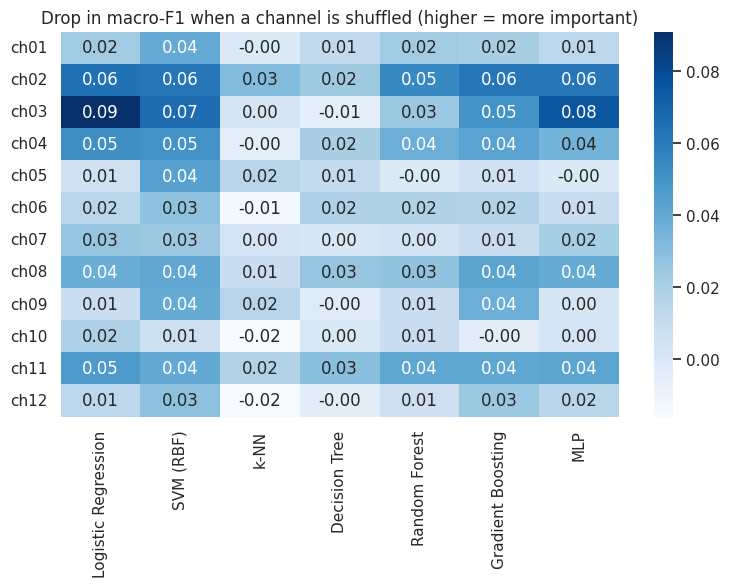

In [10]:
# channel importance (permutation, on VALIDATION set, model-agnostic)
from sklearn.inspection import permutation_importance
imp = pd.DataFrame({n: permutation_importance(m, Xva, yva, scoring="f1_macro", n_repeats=5,
                    random_state=SEED, n_jobs=-1).importances_mean for n, m in models.items()}, index=CH)
plt.figure(figsize=(9, 5)); sns.heatmap(imp, annot=True, fmt=".2f", cmap="Blues")
plt.title("Drop in macro-F1 when a channel is shuffled (higher = more important)"); plt.show()

# Which gestures are hard (for all model)

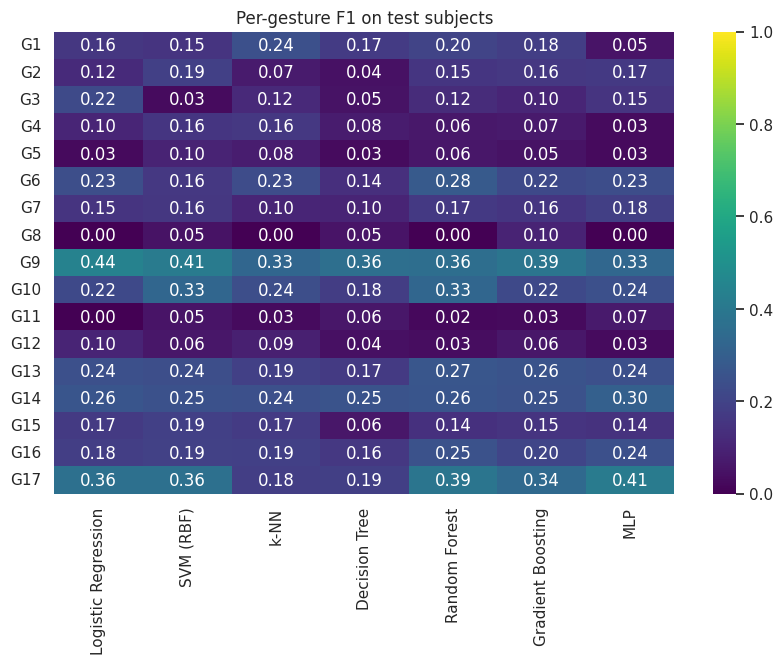

In [11]:
# per-gesture F1 for every model
f1_cls = pd.DataFrame({n: f1_score(yte, p, average=None) for n, p in preds.items()},
                      index=[f"G{c}" for c in le.classes_])
plt.figure(figsize=(10, 6)); sns.heatmap(f1_cls, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("Per-gesture F1 on test subjects"); plt.show()

# Weight of Logistic Regression, gesture x channel

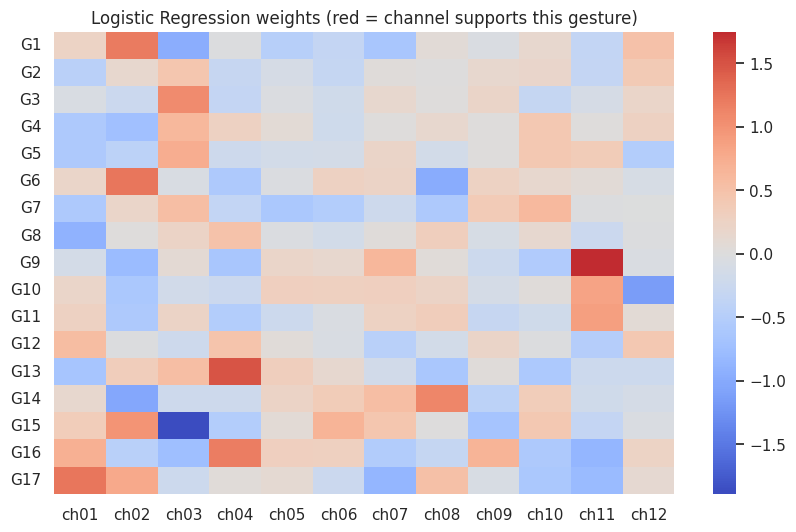

In [12]:
# which channel pushes which gesture (compare with the Task 1 class x channel heatmap)
coef = pd.DataFrame(models["Logistic Regression"].coef_, index=[f"G{c}" for c in le.classes_], columns=CH)
plt.figure(figsize=(10, 6)); sns.heatmap(coef, cmap="coolwarm", center=0)
plt.title("Logistic Regression weights (red = channel supports this gesture)"); plt.show()

# Confusion matrix of Best baseline

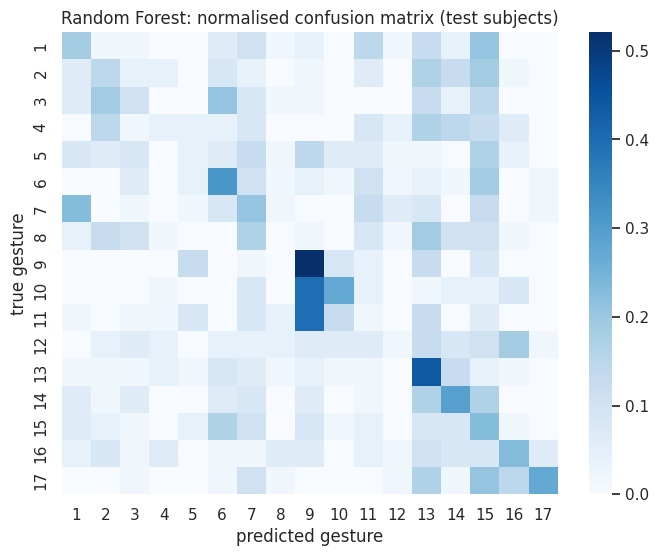

In [13]:
# confusion matrix of the best baseline
cm = confusion_matrix(yte, preds[best_name], normalize="true")
plt.figure(figsize=(8, 6))
sns.heatmap(cm, cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f"{best_name}: normalised confusion matrix (test subjects)")
plt.xlabel("predicted gesture"); plt.ylabel("true gesture"); plt.show()

## 4. Classification report, inference time and model size

In [14]:
import pickle
from sklearn.metrics import classification_report

cost = {}
for name, m in models.items():
    t0 = time.time(); m.predict(Xte)
    cost[name] = {"inference_ms_per_window": (time.time() - t0) / len(Xte) * 1000,
                  "model_size_KB": len(pickle.dumps(m)) / 1024}
cost = pd.DataFrame(cost).T
display(cost.round(3))

print(f"\nClassification report: {best_name} (best baseline)")
print(classification_report(yte, preds[best_name], target_names=[f"G{c}" for c in le.classes_], zero_division=0))

,inference_ms_per_window,model_size_KB
Logistic Regression,0.002,2.538
SVM (RBF),0.225,599.279
k-NN,0.053,475.361
Decision Tree,0.001,218.248
Random Forest,0.145,123436.495
Gradient Boosting,0.289,11082.070
MLP,0.002,137.788



Classification report: Random Forest (best baseline)
              precision    recall  f1-score   support

          G1       0.21      0.19      0.20        48
          G2       0.16      0.15      0.15        48
          G3       0.15      0.10      0.12        48
          G4       0.14      0.04      0.06        48
          G5       0.10      0.04      0.06        48
          G6       0.25      0.31      0.28        48
          G7       0.14      0.21      0.17        48
          G8       0.00      0.00      0.00        48
          G9       0.27      0.52      0.36        48
         G10       0.41      0.27      0.33        48
         G11       0.02      0.02      0.02        48
         G12       0.08      0.02      0.03        48
         G13       0.19      0.44      0.27        48
         G14       0.24      0.29      0.26        48
         G15       0.10      0.23      0.14        48
         G16       0.28      0.23      0.25        48
         G17       0.68    

## 5. Save the results for the proposed-model notebook

In [15]:
OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
results.to_csv(f"{OUT}/baseline_results.csv")
cost.to_csv(f"{OUT}/baseline_cost.csv")
np.savez(f"{OUT}/baseline_preds.npz", y_test=yte, **preds)
print("Saved baseline_results.csv, baseline_cost.csv and baseline_preds.npz to:", OUT)

Saved baseline_results.csv, baseline_cost.csv and baseline_preds.npz to: /kaggle/working


# Baseline conclusion

- **Baseline to beat:** Random Forest, test macro-F1 = 0.182 (random guess = 0.059).
- **Overfitting:** Random Forest and Gradient Boosting reach 100% train accuracy but only about 19% on new subjects. Logistic Regression has the smallest gap (0.107). The main difficulty is subject-to-subject variation, not model capacity.
- **Channels:** ch11, ch04 and ch09 are the most informative channels (ANOVA F-score).